In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report, ConfusionMatrixDisplay

In [2]:
print("DIABETES PREDICTION USING K-NEAREST NEIGHBORS")
df = pd.read_csv("diabetes.csv")
print("Dataset shape:", df.shape)
print(df.head())

DIABETES PREDICTION USING K-NEAREST NEIGHBORS
Dataset shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]


In [3]:
columns_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for column in columns_with_zero:
    df[column] = df[column].replace(0, np.nan)
    df[column] = df[column].fillna(df[column].median())
print("Missing values after cleaning:", int(df.isnull().sum().sum()))
X = df.drop(columns=["Outcome"])
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training records:", X_train.shape[0])
print("Testing records :", X_test.shape[0])

Missing values after cleaning: 0
Training records: 614
Testing records : 154


In [4]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

In [5]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print("K value:", 5)
print("Confusion Matrix:")
print(cm)
print("Accuracy :", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))

K value: 5
Confusion Matrix:
[[83 17]
 [21 33]]
Accuracy : 0.7532
Error Rate: 0.2468
Precision : 0.66
Recall    : 0.6111


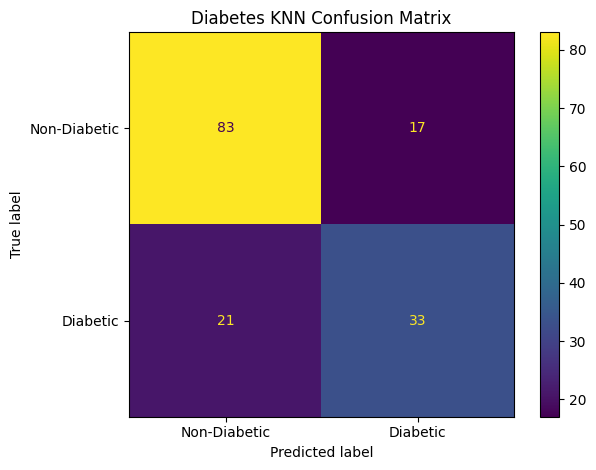

In [6]:
ConfusionMatrixDisplay(cm, display_labels=["Non-Diabetic", "Diabetic"]).plot(values_format="d")
plt.title("Diabetes KNN Confusion Matrix")
plt.tight_layout()
plt.show()